# Sugarcane Crop Cycle Analysis Using Sentinel-2

This pipeline detects harvest events, delineates crop cycles, identifies potential field renovation and successive crop stages (Plant Cane, First Ratoon, Second Ratoon, etc.), and characterizes sugarcane phenology using Sentinel-2 time series.

Figures are saved to `figures/` and processed datasets to `data/processed/`.


In [1]:
# ---- CONFIGURATION (edit here) ----
INDICES_TO_COMPUTE = ["NDVI", "EVI", "NDRE", "NDMI", "NDTI"]
INDICES_TO_PLOT = ["NDVI"]  # 1 or 2 indices
FIELDS_TO_PLOT = [1440, 1460]  # one figure per field
NDVI_THRESHOLD = 0.30  # NDVI at or below this means no live canopy
SEASON_START_MONTH = 4  # crop year opens here: 4 = sugarcane, 9 = grains
SEASON_START_DAY = 1
STRAW_COVER_MIN = 45  # cover (%) at or above which a bare date counts as straw
SHAPE_INDEX = "NDVI"  # curve the phases are drawn on
GROWTH_INDEX = "EVI"  # read at the top, where NDVI saturates (end of growth)
SMOOTHING_LAMBDA = 1000.0  # Whittaker roughness penalty: larger = smoother
SHOW_HARVESTS = True  # mark harvest dates with a red asterisk
SAVE_FIGURES = True

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cane_cycle.field_renovation import count_cuts, flag_field_renovation
from cane_cycle.harvest import build_seasons, detect_harvests
from cane_cycle.io import load_s2_csv
from cane_cycle.phenology import PHASES, add_phenology, phase_durations
from cane_cycle.plotting import (
    plot_cuts_timeseries,
    plot_index_timeseries,
    plot_phenology_timeseries,
    plot_seasons_timeseries,
    plot_smoothed_timeseries,
    plot_surface_timeseries,
)
from cane_cycle.residue import classify_surface, summarize_cycle_residue
from cane_cycle.smoothing import smooth_cycles_v2
from cane_cycle.vegetation_indices import add_indices

# Works whether this runs from the project root or from notebooks/.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = PROJECT_DIR / "data" / "raw" / "fields_example_s2.csv"
INDICES_FILE = PROJECT_DIR / "data" / "processed" / "s2_indices.csv"
HARVEST_FILE = PROJECT_DIR / "data" / "processed" / "harvest_dates.csv"
SEASONS_FILE = PROJECT_DIR / "data" / "processed" / "seasons.csv"
SURFACE_FILE = PROJECT_DIR / "data" / "processed" / "surface_state.csv"
CYCLE_RESIDUE_FILE = PROJECT_DIR / "data" / "processed" / "cycle_residue_cover.csv"
FIELD_RENOVATION_FILE = PROJECT_DIR / "data" / "processed" / "field_renovation.csv"
CYCLES_FILE = PROJECT_DIR / "data" / "processed" / "cycles_ratoon_number.csv"
SMOOTHED_FILE = PROJECT_DIR / "data" / "processed" / "smoothed_cycles.csv"
PHENOLOGY_FILE = PROJECT_DIR / "data" / "processed" / "phenology_daily.csv"
LANDMARKS_FILE = PROJECT_DIR / "data" / "processed" / "phase_landmarks.csv"
DURATIONS_FILE = PROJECT_DIR / "data" / "processed" / "phase_durations.csv"
FIGURES_DIR = PROJECT_DIR / "figures"

## 1. Data Preparation and Vegetation Indices

Sentinel-2 observations are loaded by field and date, invalid observations are removed, and band reflectance is standardized. Spectral indices are computed once and reused throughout the pipeline.

| Index | Main application |
|---|---|
| NDVI | Harvest detection and cycle shape |
| EVI | End-of-growth identification |
| NDRE | Vegetation monitoring (visualization only) |
| NDMI | Cloud discrimination |
| NDTI | Residue cover and renovation assessment |


In [3]:
df = load_s2_csv(RAW_FILE)
print(f"{len(df)} rows, fields: {sorted(df['field_id'].unique())}")
print(f"from {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
df.head(2)

964 rows, fields: [np.int64(1440), np.int64(1460)]
from 2019-01-10 to 2026-09-25


C:\Users\ju_fo\AppData\Local\Temp\ipykernel_26520\1777768122.py:1: UserWarning: Dropped 2 rows with unreadable band values on 1 dates: 2026-09-21
  df = load_s2_csv(RAW_FILE)


,fonte,date,field_id,granuleID,pixelTotal,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,coverage_pct
0,S2,2019-01-10,1440,L2A_T22K,4599,0.060076,0.080203,0.106059,0.147571,0.184043,0.212009,0.239522,0.249682,0.273818,0.417225,0.328715,100.0
1,S2,2019-01-15,1440,L2A_T22K,4599,0.569196,0.488870,0.464344,0.434051,0.493739,0.540574,0.558158,0.547149,0.566092,0.375156,0.358218,100.0


In [4]:
df = add_indices(df, indices=INDICES_TO_COMPUTE)

INDICES_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(INDICES_FILE, index=False)

df[INDICES_TO_COMPUTE].describe().round(3)

,NDVI,EVI,NDRE,NDMI,NDTI
count,964.000,964.000,964.000,964.000,964.000
mean,0.384,0.223,0.281,0.073,0.161
std,0.219,2.337,0.175,0.164,0.089
min,-0.106,-53.372,-0.089,-0.291,-0.083
25%,0.195,0.166,0.137,-0.076,0.095
50%,0.364,0.293,0.261,0.080,0.149
75%,0.576,0.446,0.424,0.203,0.238
max,0.807,5.453,0.653,0.593,0.348


## 2. Harvest Detection and Crop Cycle Delineation

Harvest candidates require **B11 > B8A** and **NDVI ≤ `NDVI_THRESHOLD`** in the same observation. A new harvest is recorded only after canopy recovery, preventing repeated detections during a bare-soil period.

`build_seasons` delineates crop cycles between successive harvests. Incomplete boundary cycles are retained; `SEASON_START_MONTH` controls crop-year labels, not harvest dates.


In [5]:
harvests = detect_harvests(
    df,
    ndvi_max=NDVI_THRESHOLD,
    start_month=SEASON_START_MONTH,
    start_day=SEASON_START_DAY,
)
harvests.to_csv(HARVEST_FILE, index=False)
harvests.head(5)

,field_id,season,harvest_date,ndvi_at_harvest,cycle_peak_ndvi
0,1440,2020/21,2020-05-19,0.237544,0.768429
1,1440,2021/22,2021-09-01,0.211026,0.777985
2,1440,2022/23,2022-11-20,0.158708,0.739919
3,1440,2023/24,2023-09-01,0.171239,0.683287
4,1440,2025/26,2025-06-17,0.236859,0.794166


In [6]:
seasons = build_seasons(
    df, harvests, start_month=SEASON_START_MONTH, start_day=SEASON_START_DAY
)
seasons.to_csv(SEASONS_FILE, index=False)
seasons.head(5)

,field_id,season,start_date,end_date,duration_days,open_season
0,1440,2020/21,2019-01-10,2020-05-19,495,True
1,1440,2021/22,2020-05-19,2021-09-01,470,False
2,1440,2022/23,2021-09-01,2022-11-20,445,False
3,1440,2023/24,2022-11-20,2023-09-01,285,False
4,1440,2025/26,2023-09-01,2025-06-17,655,False


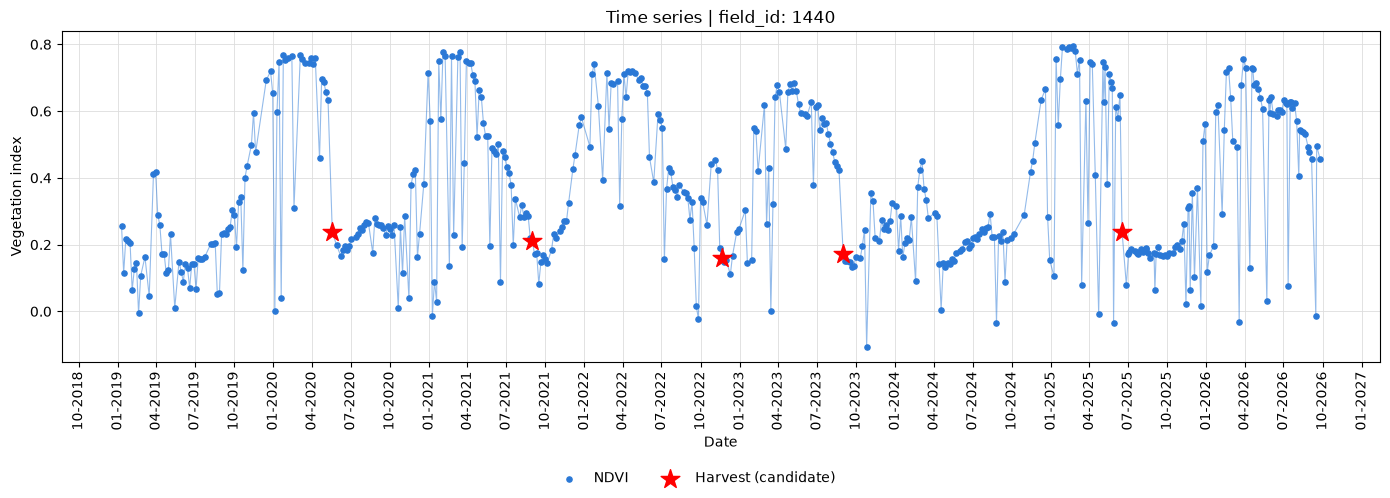

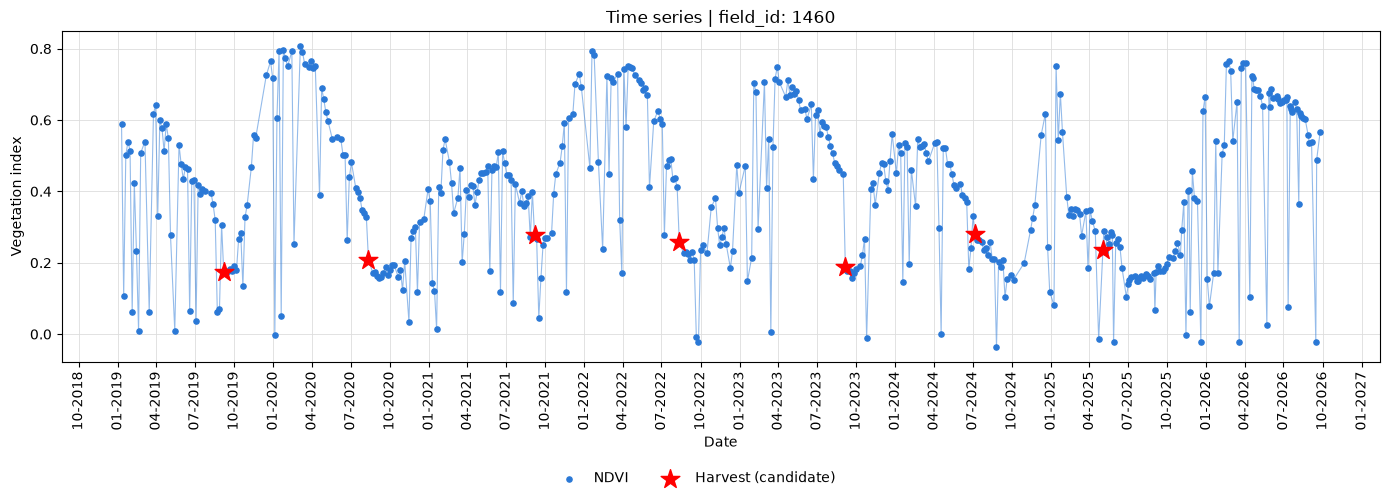

In [7]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        file_name = f"timeseries_{field_id}_{'_'.join(INDICES_TO_PLOT)}.png"
        save_path = FIGURES_DIR / file_name
    plot_index_timeseries(
        df,
        INDICES_TO_PLOT,
        field_id,
        harvests=harvests if SHOW_HARVESTS else None,
        save_path=save_path,
    )
    plt.show()

### Temporal Profiles by Crop Cycle

Each cycle is shown in a distinct color. Black marks the beginning of the first cycle and red marks cycle endings; shared harvest boundaries are not marked twice. The final red marker indicates the end of the observation period, **not a detected harvest**.


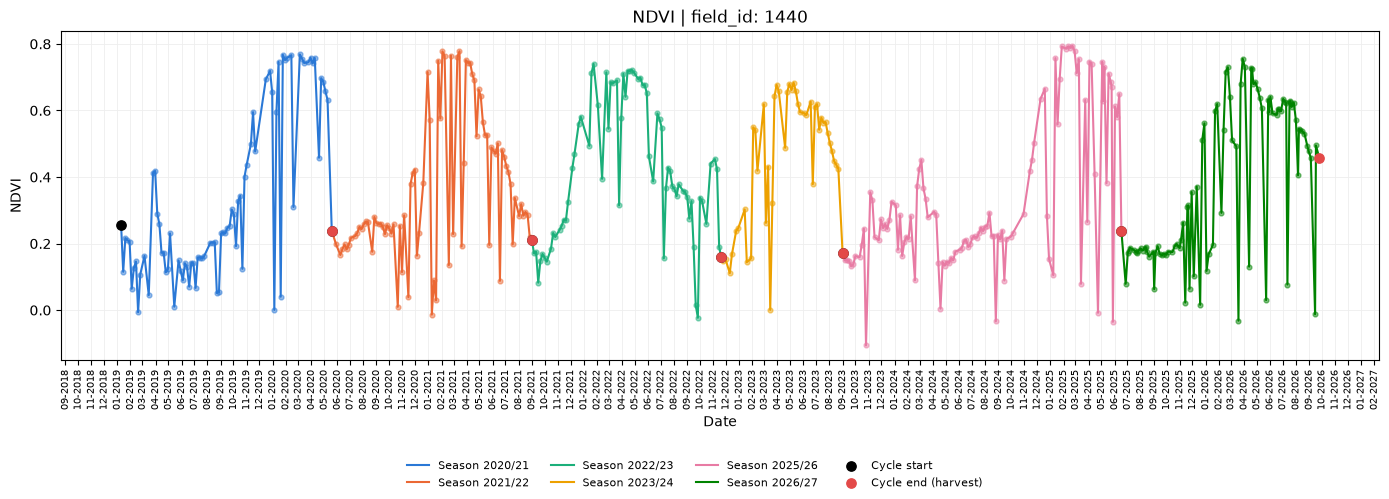

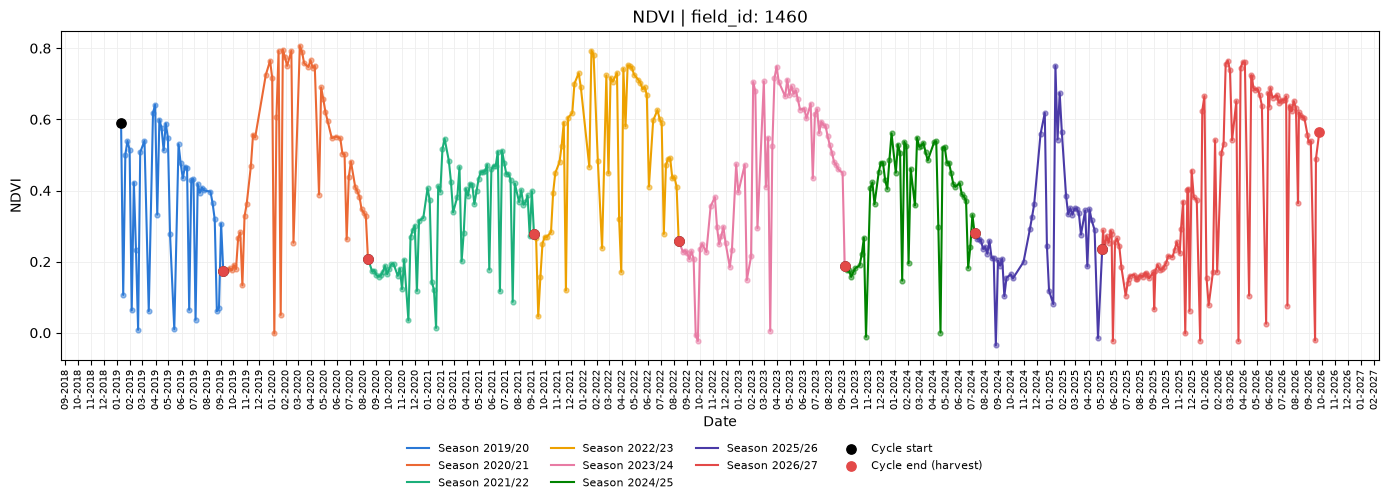

In [8]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        save_path = FIGURES_DIR / f"seasons_{field_id}_{INDICES_TO_PLOT[0]}.png"
    plot_seasons_timeseries(
        df, INDICES_TO_PLOT[0], field_id, seasons, save_path=save_path
    )
    plt.show()

## 3. Sugarcane Field Renovation and Crop Stage Identification

After planting, sugarcane develops as **Plant Cane**, followed by successive ratoon crops (**First Ratoon, Second Ratoon**, etc.) until field renovation restarts the sequence. The pipeline uses **residue cover** and an intermediate **surface classification** to infer potential renovation events and identify these crop stages.

### 3.1 Residue Cover

NDTI is converted to estimated residue cover (0-100%) using an adaptation of the [Embrapa methodology for ZARC Management Levels (DOC-454, 2023)](https://www.infoteca.cnptia.embrapa.br/infoteca/handle/doc/1156802), with scaling limits defined by the mean plus or minus 3 standard deviations. The stretch is fitted only over dates with no canopy, since standing cane has the highest NDTI of all and would otherwise set the fully-covered anchor. This is a remote-sensing estimate, not a field measurement.

Cover is computed per observation here, and summarized per crop cycle in 3.3, where it decides renovation.

In [9]:
df = classify_surface(df, straw_cover_min=STRAW_COVER_MIN)
df.to_csv(SURFACE_FILE, index=False)

df[["date", "field_id", "NDTI", "residue_cover_pct", "surface"]].head()

,date,field_id,NDTI,residue_cover_pct,surface
0,2019-01-10,1440,0.118656,57.984687,straw
1,2019-01-15,1440,0.023096,NaN,cloud
2,2019-01-20,1440,0.124025,59.762245,straw
3,2019-01-25,1440,0.138263,64.476242,straw
4,2019-01-30,1440,0.120475,58.587036,straw


### 3.2 Surface Classification

Each satellite observation is labelled to distinguish residue-covered and exposed soil after harvest, providing supporting evidence for potential renovation events. Cloud detection takes priority to avoid confusing obscured surfaces with canopy or straw.

| Class | Classification rule |
|---|---|
| `canopy` | NIR > SWIR or NDVI above the harvest threshold |
| `straw` | No canopy; estimated residue cover ≥ `STRAW_COVER_MIN` |
| `bare soil` | No canopy; estimated residue cover < `STRAW_COVER_MIN` |
| `cloud` | High B1 reflectance **and** NDMI; overrides other classes |


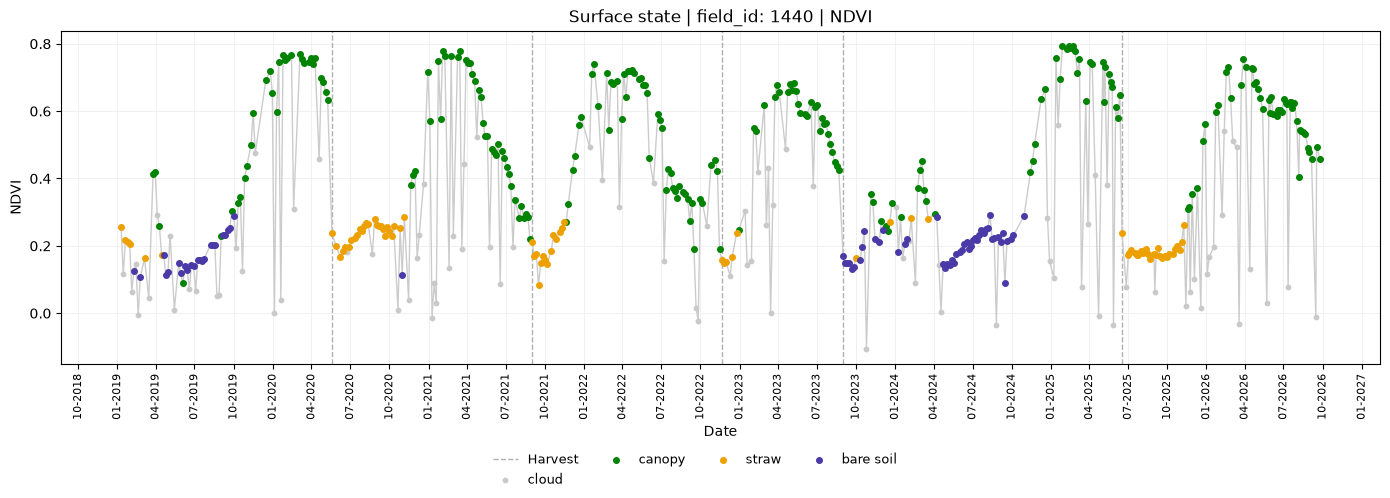

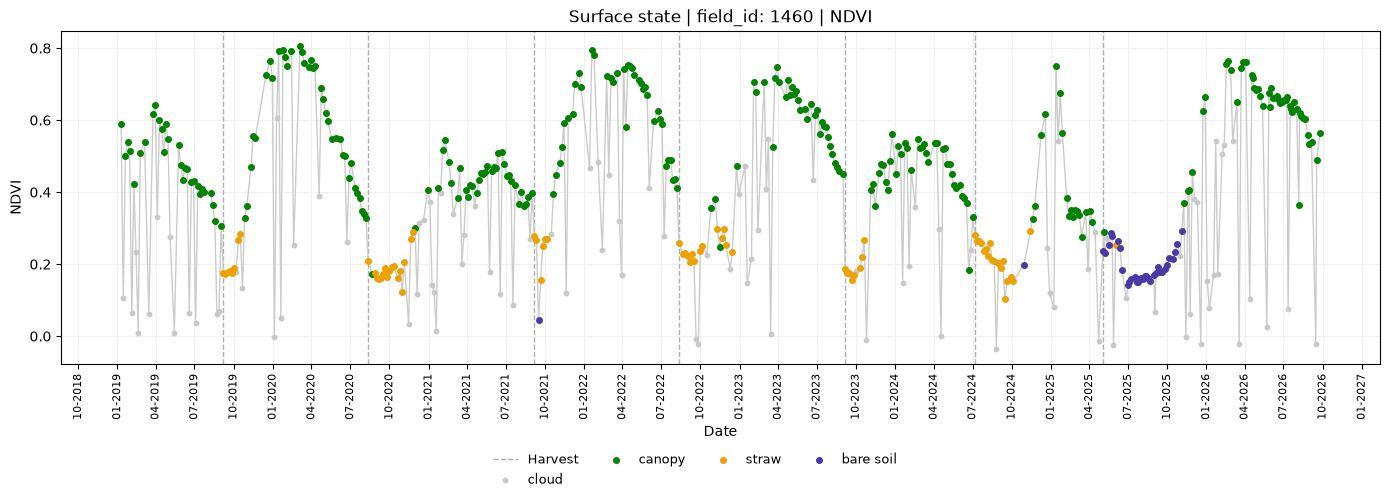

In [10]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        save_path = FIGURES_DIR / f"surface_{field_id}_{INDICES_TO_PLOT[0]}.png"
    plot_surface_timeseries(
        df, INDICES_TO_PLOT[0], field_id, harvests=harvests, save_path=save_path
    )
    plt.show()

### 3.3 Renovation Detection and Ratoon Sequence

A cycle is flagged as a **potential renovation** when the median estimated residue cover over its bare stretch is below `STRAW_COVER_MIN` (default: **45%**), consistent with residue removal or incorporation during soil preparation.

The window is the cycle's own bare period rather than a fixed number of days after the cut, for two reasons: tillage keeps the ground exposed for months, well past any fixed window, and the first cycle of the record opens on the limit of the series rather than on a detected harvest, so a window anchored to a cut cannot be applied to it.

A cycle whose bare stretch holds fewer than `CYCLE_MIN_BARE_IMAGES` observations is left undecided. This separates a first cycle the record caught during the bare period, which can be read like any other, from one it caught with the canopy already closed.

The flagged cycle is the **Plant Cane**, followed by **First Ratoon**, **Second Ratoon**, and subsequent ratoon crops. Stages preceding the first detected renovation remain undefined because the field's earlier history is unknown.

In [11]:
cycle_residue = summarize_cycle_residue(df, seasons)
cycle_residue.to_csv(CYCLE_RESIDUE_FILE, index=False)

field_renovation = flag_field_renovation(cycle_residue, cover_max=STRAW_COVER_MIN)
field_renovation.to_csv(FIELD_RENOVATION_FILE, index=False)
field_renovation

,field_id,season,start_date,n_images,bare_soil_pct,residue_cover_pct,zarc_class,enough_images,field_renovation
0,1440,2020/21,2019-01-10,30,76.666667,27.779024,<45%,True,True
1,1440,2021/22,2020-05-19,28,3.571429,68.058040,60-75%,True,False
2,1440,2022/23,2021-09-01,15,0.000000,68.143489,60-75%,True,False
3,1440,2023/24,2022-11-20,6,16.666667,68.182589,60-75%,True,False
4,1440,2025/26,2023-09-01,53,90.566038,33.301546,<45%,True,True
5,1440,2026/27,2025-06-17,28,0.000000,61.895358,60-75%,True,False
6,1460,2019/20,2019-01-10,1,0.000000,51.632742,45-60%,False,<NA>
7,1460,2020/21,2019-09-07,9,0.000000,63.770330,60-75%,True,False
8,1460,2021/22,2020-08-12,18,0.000000,62.436825,60-75%,True,False
9,1460,2022/23,2021-09-06,8,12.500000,62.466363,60-75%,True,False


In [12]:
cycles = count_cuts(seasons, field_renovation)
cycles.to_csv(CYCLES_FILE, index=False)
cycles

,field_id,season,start_date,end_date,duration_days,open_season,ratoon_number,stage
0,1440,2020/21,2019-01-10,2020-05-19,495,True,0,plant cane
1,1440,2021/22,2020-05-19,2021-09-01,470,False,1,1st ratoon
2,1440,2022/23,2021-09-01,2022-11-20,445,False,2,2nd ratoon
3,1440,2023/24,2022-11-20,2023-09-01,285,False,3,3rd ratoon
4,1440,2025/26,2023-09-01,2025-06-17,655,False,0,plant cane
5,1440,2026/27,2025-06-17,2026-09-25,465,True,1,1st ratoon
6,1460,2019/20,2019-01-10,2019-09-07,240,True,<NA>,NaN
7,1460,2020/21,2019-09-07,2020-08-12,340,False,<NA>,NaN
8,1460,2021/22,2020-08-12,2021-09-06,390,False,<NA>,NaN
9,1460,2022/23,2021-09-06,2022-08-12,340,False,<NA>,NaN


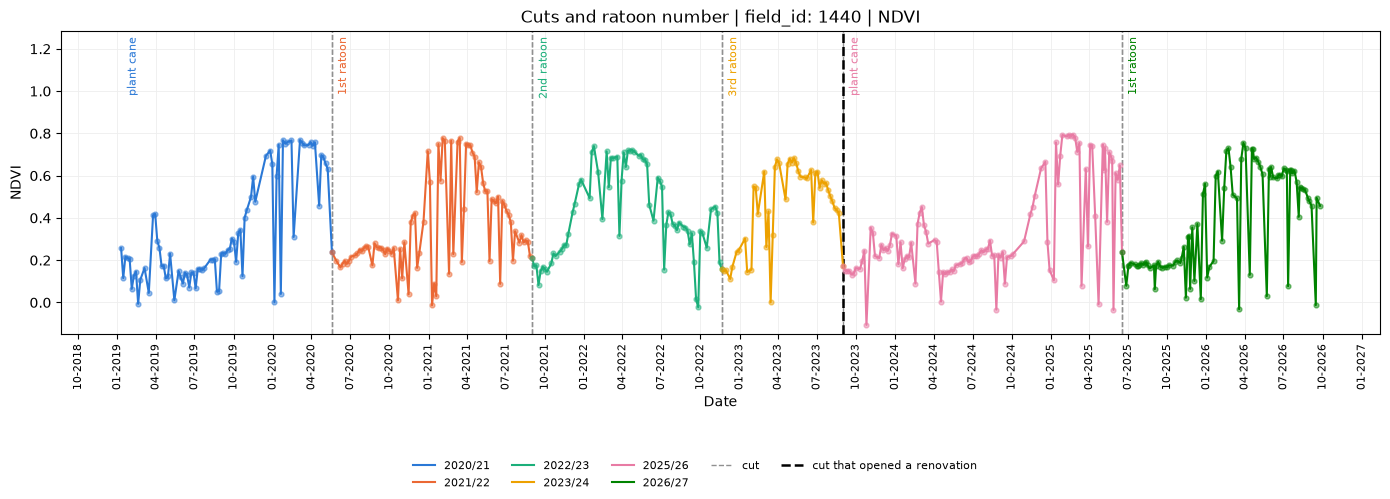

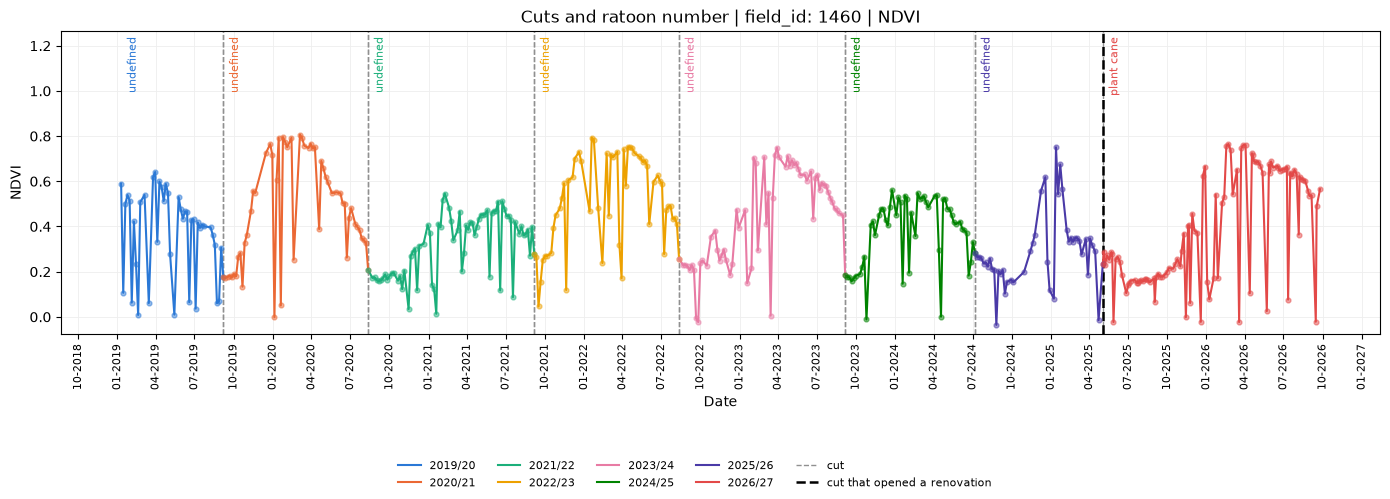

In [13]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        save_path = FIGURES_DIR / f"ratoon_cycles_{field_id}_{INDICES_TO_PLOT[0]}.png"
    plot_cuts_timeseries(
        df, INDICES_TO_PLOT[0], field_id, cycles,
        harvests=harvests, save_path=save_path,
    )
    plt.show()

## 4. Phenological Phase Classification

Phenological phases are identified from the shape of the smoothed profile. **Time-series smoothing is a required preprocessing step** to reduce noise before the phase boundaries are read.

### 4.1 Time-Series Smoothing

Whittaker smoothing (Eilers, 2003) is applied separately to each crop cycle, on a daily grid. `SMOOTHING_LAMBDA` controls the smoothness penalty; missing and cloudy observations receive zero weight, so the fit fills those days itself. The figure shows the fitted curve against the observations it came from.

In [14]:
smoothed = smooth_cycles_v2(df, seasons, index=SHAPE_INDEX, lam=SMOOTHING_LAMBDA)
smoothed.to_csv(SMOOTHED_FILE, index=False)

print(f"{len(smoothed)} daily values over "
      f"{smoothed.groupby(['field_id', 'season']).ngroups} cycles")
smoothed.head()

5644 daily values over 14 cycles


C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:8

,field_id,season,date,NDVI_smooth,observed
0,1440,2020/21,2019-01-10,0.257232,True
1,1440,2020/21,2019-01-11,0.253480,False
2,1440,2020/21,2019-01-12,0.249725,False
3,1440,2020/21,2019-01-13,0.245967,False
4,1440,2020/21,2019-01-14,0.242204,False


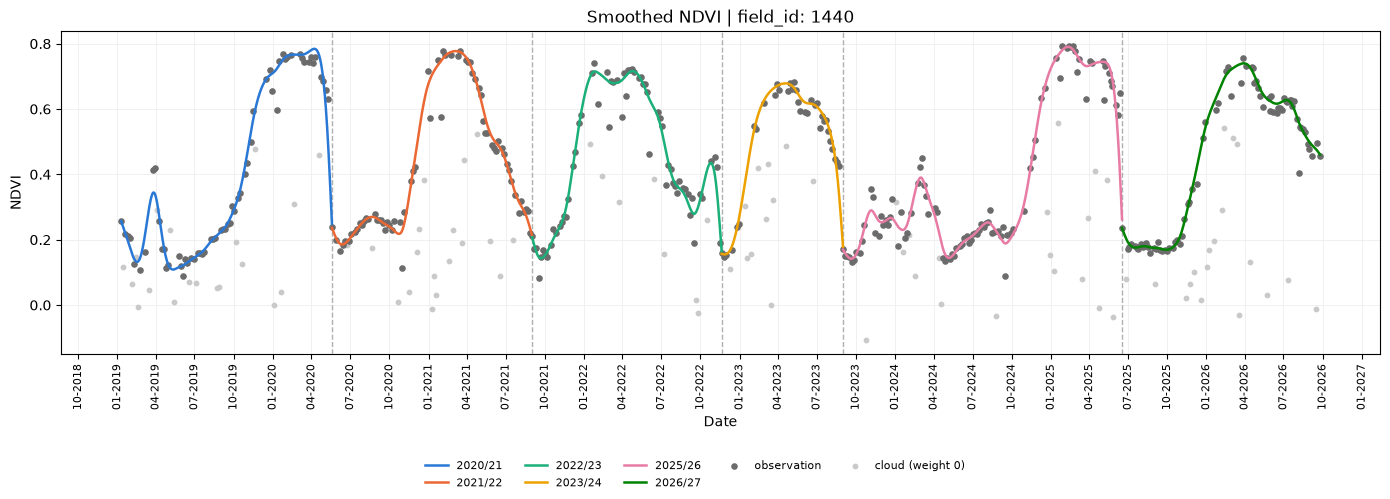

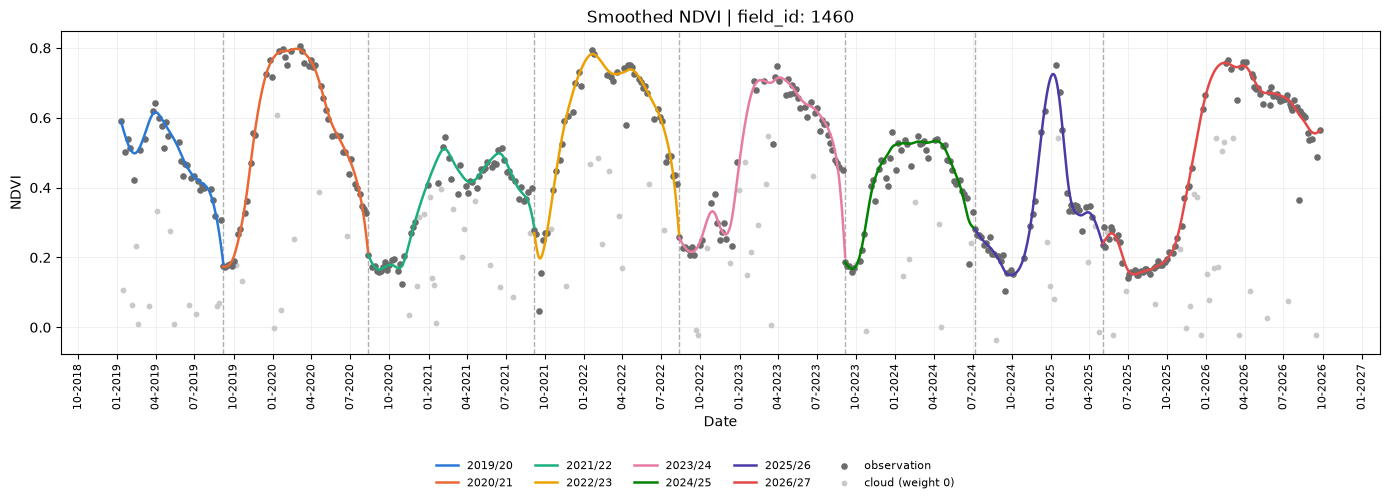

In [15]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        save_path = FIGURES_DIR / f"smoothed_{field_id}_{SHAPE_INDEX}.png"
    plot_smoothed_timeseries(
        df, smoothed, SHAPE_INDEX, field_id, harvests=harvests, save_path=save_path
    )
    plt.show()

### 4.2 Phenological Phase Detection

Three phases are delineated from the smoothed temporal profiles, split at the peak of `GROWTH_INDEX`. EVI is used for the peak because NDVI saturates near canopy maximum and its peak drifts across the plateau. Cycles without identifiable crop development remain unclassified.

| Phase | Starting landmark | Agronomic interpretation |
|---|---|---|
| `post_harvest` | Harvest | Early regrowth below visible canopy |
| `growth` | Last bare date before the peak | Canopy establishment and stalk elongation |
| `maturation` | Peak of `GROWTH_INDEX` | Reduced vegetative growth and sucrose accumulation |

In [16]:
curve, landmarks = add_phenology(
    df,
    seasons,
    shape_index=SHAPE_INDEX,
    growth_index=GROWTH_INDEX,
)
curve.to_csv(PHENOLOGY_FILE, index=False)
landmarks.to_csv(LANDMARKS_FILE, index=False)
landmarks

C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:8

,field_id,season,cut,bare_end,cessation,next_cut,classified
0,1440,2020/21,2019-01-10,2019-10-02,2020-02-06,2020-05-19,True
1,1440,2021/22,2020-05-19,2020-11-05,2021-02-09,2021-09-01,True
2,1440,2022/23,2021-09-01,2021-11-15,2022-01-23,2022-11-20,True
3,1440,2023/24,2022-11-20,2022-12-25,2023-03-21,2023-09-01,True
4,1440,2025/26,2023-09-01,2024-10-30,2025-01-31,2025-06-17,True
5,1440,2026/27,2025-06-17,2025-11-09,2026-03-01,2026-09-25,True
6,1460,2019/20,2019-01-10,NaT,2019-01-10,2019-09-07,False
7,1460,2020/21,2019-09-07,2019-10-17,2020-02-05,2020-08-12,True
8,1460,2021/22,2020-08-12,2020-11-25,2021-02-08,2021-09-06,True
9,1460,2022/23,2021-09-06,2021-10-06,2022-01-14,2022-08-12,True


C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:87: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  second_difference = sparse.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
C:\Users\ju_fo\OneDrive\Documentos\Python Scripts\cane_cycle\src\cane_cycle\smoothing.py:8

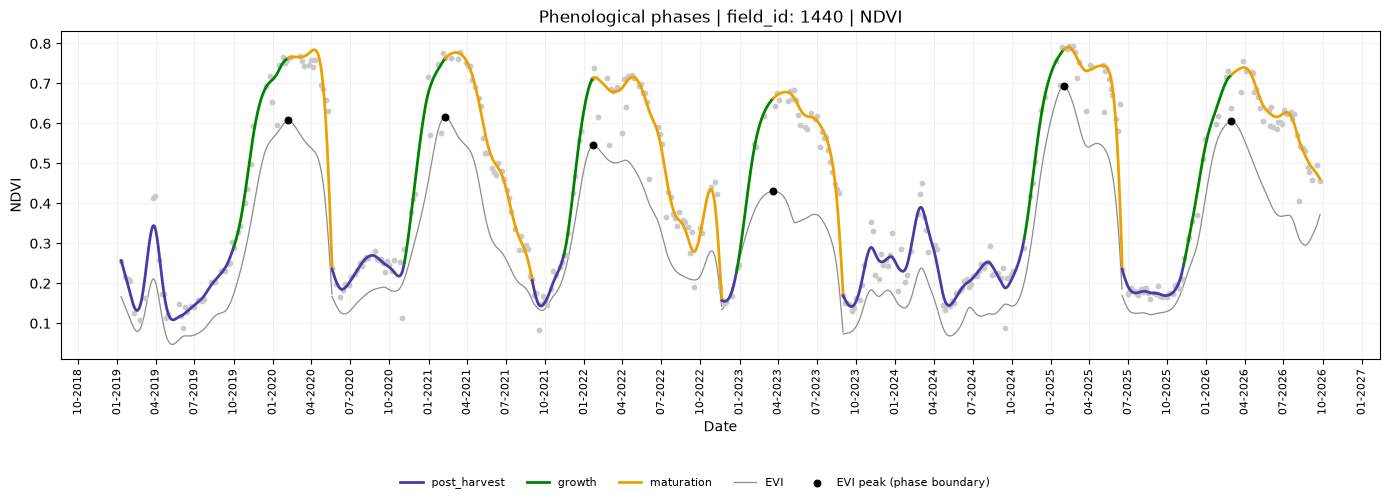

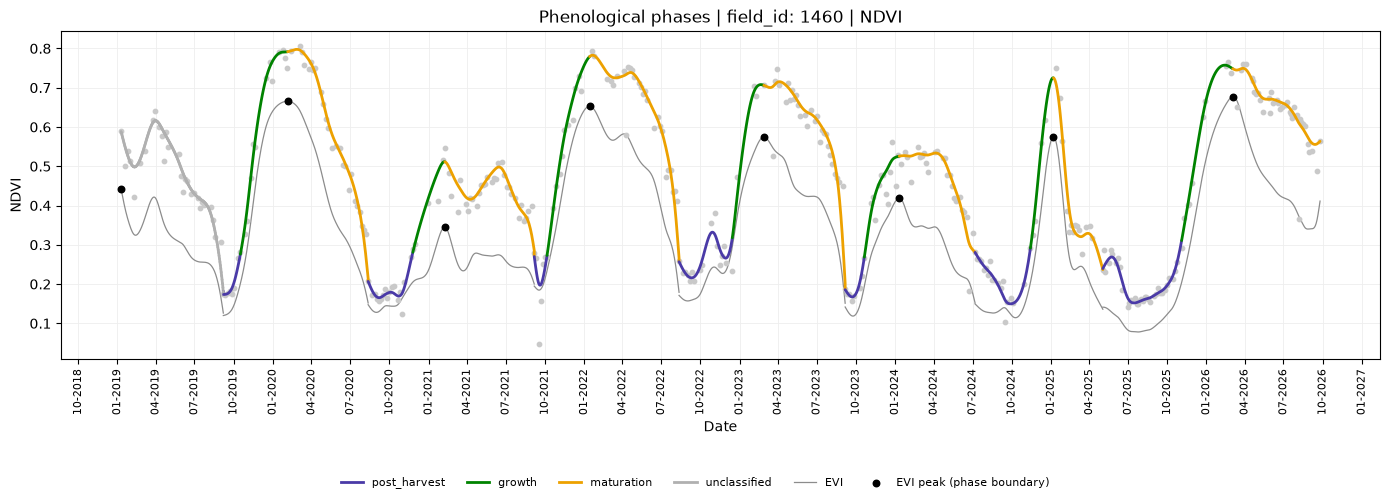

In [17]:
# The phase boundary is the peak of GROWTH_INDEX, so its curve is drawn behind
# the one the phases are painted on, with that peak marked.
growth_curve = smooth_cycles_v2(df, seasons, index=GROWTH_INDEX, lam=SMOOTHING_LAMBDA)

for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        save_path = FIGURES_DIR / f"phenology_{field_id}_{SHAPE_INDEX}.png"
    plot_phenology_timeseries(
        df,
        curve,
        SHAPE_INDEX,
        field_id,
        growth=growth_curve,
        growth_index=GROWTH_INDEX,
        save_path=save_path,
    )
    plt.show()

### 4.3 Phase Durations and Cycle Comparison

Phase durations reveal differences in development across crop cycles. Deviations from each field's median highlight unusually short or long phases and provide time windows for subsequent climate analyses.

In [18]:
durations = phase_durations(landmarks)
durations["cycle_days"] = durations[PHASES].sum(axis=1)
durations.to_csv(DURATIONS_FILE, index=False)
durations

,field_id,season,post_harvest,growth,maturation,cycle_days
0,1440,2020/21,265,127,103,495
1,1440,2021/22,170,96,204,470
2,1440,2022/23,75,69,301,445
3,1440,2023/24,35,86,164,285
4,1440,2025/26,425,93,137,655
5,1440,2026/27,145,112,208,465
7,1460,2020/21,40,111,189,340
8,1460,2021/22,105,75,210,390
9,1460,2022/23,30,100,210,340
10,1460,2023/24,125,74,191,390


In [19]:
# How far each cycle falls from what is normal for its own field, in days.
# Positive = the phase ran longer than usual, negative = it was cut short.
typical = durations.groupby("field_id")[PHASES].transform("median")
deviation = (durations[PHASES] - typical).round().astype("Int64")
atypical = pd.concat([durations[["field_id", "season"]], deviation], axis=1)
atypical

,field_id,season,post_harvest,growth,maturation
0,1440,2020/21,108,32,-81
1,1440,2021/22,12,2,20
2,1440,2022/23,-82,-26,117
3,1440,2023/24,-122,-8,-20
4,1440,2025/26,268,-2,-47
5,1440,2026/27,-12,18,24
7,1460,2020/21,-65,29,-2
8,1460,2021/22,0,-7,19
9,1460,2022/23,-75,18,19
10,1460,2023/24,20,-8,0


In [20]:
# The maturation window of every cycle, shortest first: the cycles at the top
# were cut while the cane was still filling, the ones at the bottom stood
# longest before the mill took them.
durations[["field_id", "season", "maturation", "cycle_days"]].sort_values(
    ["field_id", "maturation"]
)

,field_id,season,maturation,cycle_days
0,1440,2020/21,103,495
4,1440,2025/26,137,655
3,1440,2023/24,164,285
1,1440,2021/22,204,470
5,1440,2026/27,208,465
2,1440,2022/23,301,445
12,1460,2025/26,116,300
11,1460,2024/25,178,305
7,1460,2020/21,189,340
10,1460,2023/24,191,390
